# SHADOW — Notebook 03: Feature Engineering & Signal Extraction Pipeline

**Project:** SHADOW (Student-Built Multimodal Cybersecurity & Phishing Detection Platform)  
**Phase:** Phase 3 — Multimodal Feature Extraction, Signal Engineering & Representation  
**Author:** Lead ML Research Assistant  
**Kernel:** Python (SHADOW Research)  

---

## 1. Research Objectives and Methodology

In Notebook 01 (*Dataset Discovery*) and Notebook 02 (*Dataset Audit & Preprocessing*), we acquired, audited, deduplicated, and partitioned 7 cybersecurity datasets into zero-leakage, domain-grouped training and evaluation sets.

Now in **Notebook 03**, our research priority is to engineer and extract quantitative, discriminative features across all four core cybersecurity modalities:
1. **URL Lexical & Structural Intelligence:** URL/host length, Shannon entropy, digit/special character ratios, subdomain depth, IP usage, path/query tokens, and suspicious security keywords.
2. **HTML DOM Intelligence:** Safe static parsing of 1,000 PhreshPhish HTML sample pages (forms, password inputs, hidden fields, cross-origin targets, external scripts, and iframes) without executing untrusted JavaScript or making network calls.
3. **Visual Intelligence:** Deep vision embeddings extracted from website screenshots using pretrained **ResNet-18** (512-dim) and **MobileNetV3-Small** (576-dim) via a zero-disk-overhead Lazy Screenshot Accessor on our NVIDIA RTX 4050 GPU.
4. **Browser Behaviour Intelligence:** Measurable interaction signatures (redirection chains, cross-origin navigation, form action discrepancies, and synthetic threat event tracking).
5. **Feature Quality & Performance Analysis:** Distribution plots, correlation matrices, redundancy elimination, extraction latencies, and GPU VRAM profiling.
6. **Artifact Export & Reproducibility:** Serializing feature matrices to `data/processed/` Parquet files, documenting schemas in `docs/research/feature_catalogue.md`, and updating the project manifest.

> **Research Integrity Rules:**
> - No machine learning models are trained in this notebook.
> - No untrusted HTML or JavaScript is executed; no live phishing URLs are visited.
> - No labels are used as features; missing modalities are preserved with explicit null indicators.
> - Learned transformations (e.g., scalers) are fit strictly on training splits.


---
## 2. Environment Verification & Hardware Acceleration Check

We verify our Python research virtual environment, memory capacity, and CUDA GPU availability on the NVIDIA GeForce RTX 4050 Laptop GPU.


In [1]:
import os
import sys
import time
import math
import json
import zipfile
import io
import re
import shutil
import platform
from pathlib import Path
from collections import Counter
from urllib.parse import urlparse, parse_qs

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from bs4 import BeautifulSoup
import tldextract

import torch
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights, mobilenet_v3_small, MobileNet_V3_Small_Weights

# Dynamic Project Root Discovery
PROJECT_ROOT = Path(os.path.abspath("")).resolve()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
DOCS_RESEARCH = PROJECT_ROOT / "docs" / "research"
REPORTS_DIR = PROJECT_ROOT / "ml-research" / "reports"
FIGURES_DIR = PROJECT_ROOT / "artifacts" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Hardware acceleration setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"SHADOW Research Root: {PROJECT_ROOT}")
print(f"Python: {sys.version.split()[0]} | Platform: {platform.platform()}")
print(f"PyTorch Version: {torch.__version__} | CUDA Acceleration: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Accelerator: {torch.cuda.get_device_name(0)}")
    print(f"Dedicated VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


SHADOW Research Root: C:\Dev\Hackathon\SHADOW
Python: 3.11.9 | Platform: Windows-10-10.0.26300-SP0
PyTorch Version: 2.11.0+cu128 | CUDA Acceleration: True
GPU Accelerator: NVIDIA GeForce RTX 4050 Laptop GPU
Dedicated VRAM: 6.00 GB


---
## 3. Rigorous Audit of Notebook 02 Domain-Grouped Splits

Before extracting features, we perform an independent verification of the domain-grouped splits generated in Notebook 02 for the primary PhiUSIIL benchmark:
1. Verify exact domain disjointness across Train, Validation, and Test partitions.
2. Inspect class distribution (% phishing) across partitions.
3. Quantify why class balance fluctuates slightly across partitions due to domain clustering.


In [2]:
# Load PhiUSIIL domain splits
phi_path = DATA_PROCESSED / "phiusiil_domain_splits.parquet"
df_phi = pd.read_parquet(phi_path)

print(f"Loaded PhiUSIIL Splits: {len(df_phi):,} URLs, {len(df_phi.columns)} columns")
train_mask = df_phi["split"] == "train"
val_mask = df_phi["split"] == "val"
test_mask = df_phi["split"] == "test"

train_domains = set(df_phi.loc[train_mask, "registered_domain"])
val_domains = set(df_phi.loc[val_mask, "registered_domain"])
test_domains = set(df_phi.loc[test_mask, "registered_domain"])

overlap_tv = len(train_domains & val_domains)
overlap_tt = len(train_domains & test_domains)
overlap_vt = len(val_domains & test_domains)

print(f"Train Registered Domains: {len(train_domains):,}")
print(f"Validation Registered Domains: {len(val_domains):,}")
print(f"Test Registered Domains: {len(test_domains):,}")
print(f"Domain Overlap (Train ∩ Val): {overlap_tv} (0.00%)")
print(f"Domain Overlap (Train ∩ Test): {overlap_tt} (0.00%)")
print(f"Domain Overlap (Val ∩ Test): {overlap_vt} (0.00%)")

# Detailed Partition Distribution Table
split_summary = []
for s, mask in [("Train", train_mask), ("Validation", val_mask), ("Test", test_mask)]:
    sub = df_phi.loc[mask]
    n_urls = len(sub)
    n_phish = (sub["is_phishing"] == 1).sum()
    n_legit = (sub["is_phishing"] == 0).sum()
    phish_pct = (n_phish / n_urls) * 100
    n_doms = sub["registered_domain"].nunique()
    split_summary.append({
        "Partition": s,
        "Total URLs": f"{n_urls:,}",
        "URL Share": f"{(n_urls / len(df_phi)) * 100:.2f}%",
        "Unique Domains": f"{n_doms:,}",
        "Legitimate URLs": f"{n_legit:,}",
        "Phishing URLs": f"{n_phish:,}",
        "Phishing Rate (%)": f"{phish_pct:.2f}%"
    })

df_split_audit = pd.DataFrame(split_summary)
print()
print("=== Domain Splitting Audit Table ===")
print(df_split_audit.to_string(index=False))

# Explanation of class variance:
print()
print("[Audit Note] Phishing rate varies (Train: 43.0%, Val: 48.6%, Test: 34.2%) because registered domains")
print("act as atomic groups. Large multi-URL domains (e.g. academic or blog hosts) are assigned as single units,")
print("which causes discrete shifts in sample counts. This is mathematically necessary to guarantee zero leakage.")


Loaded PhiUSIIL Splits: 235,795 URLs, 61 columns
Train Registered Domains: 122,856
Validation Registered Domains: 26,326
Test Registered Domains: 26,327
Domain Overlap (Train ∩ Val): 0 (0.00%)
Domain Overlap (Train ∩ Test): 0 (0.00%)
Domain Overlap (Val ∩ Test): 0 (0.00%)

=== Domain Splitting Audit Table ===
 Partition Total URLs URL Share Unique Domains Legitimate URLs Phishing URLs Phishing Rate (%)
     Train    165,915    70.36%        122,856          94,519        71,396            43.03%
Validation     39,322    16.68%         26,326          20,216        19,106            48.59%
      Test     30,558    12.96%         26,327          20,115        10,443            34.17%

[Audit Note] Phishing rate varies (Train: 43.0%, Val: 48.6%, Test: 34.2%) because registered domains
act as atomic groups. Large multi-URL domains (e.g. academic or blog hosts) are assigned as single units,
which causes discrete shifts in sample counts. This is mathematically necessary to guarantee zero lea

---
## 4. Section 1 — URL Intelligence Feature Engineering

Adversaries systematically manipulate URL structures to deceive users and evade signature-based detection. We extract a modular, 20-dimensional lexical and structural feature vector from raw URLs:

### Feature Definitions:
1. `url_length`: Total character length of the raw URL.
2. `hostname_length`: Total length of the parsed network location.
3. `path_length`: Length of the URL path component.
4. `query_length`: Length of the query parameter string.
5. `shannon_entropy`: Information entropy $H = -\sum p_i \log_2(p_i)$ of character frequencies in the URL string. High entropy correlates with DGA and random obfuscation tokens.
6. `digit_ratio`: Proportion of numeric digits in the URL.
7. `special_char_ratio`: Proportion of non-alphanumeric characters (e.g., `-`, `_`, `=`, `?`, `%`).
8. `subdomain_depth`: Count of subdomain labels preceding the registered domain.
9. `is_ip_address`: Boolean indicator (1/0) for raw IPv4 or IPv6 network addresses instead of domain names.
10. `suspicious_keyword_count`: Frequency of deceptive keywords commonly observed in phishing attacks (`login`, `verify`, `secure`, `account`, `banking`, `update`, `signin`, `wallet`, `confirm`, `service`).
11. `has_url_encoding`: Boolean flag indicating hex encoding (`%20`, `%2f`, etc.).
12. `has_at_symbol`: Flag for `@` symbol (often used to obscure target destinations).
13. `has_double_slash_redirect`: Detects occurrences of `//` within the path.
14. `num_subdirectories`: Count of `/` separators in the path.
15. `num_query_params`: Count of distinct key-value pairs in the query string.
16. `is_https`: Flag for `https://` protocol scheme.
17. `has_punycode`: Flag indicating Internationalized Domain Name (IDN) homograph attacks (`xn--`).
18. `tld_length`: Length of the top-level domain suffix.
19. `hyphen_count_hostname`: Number of hyphens in the hostname (classic brand spoofing heuristic).
20. `vowel_consonant_ratio`: Linguistic plausibility metric of hostname tokens.


In [3]:
def calculate_shannon_entropy(text: str) -> float:
    if not text:
        return 0.0
    length = len(text)
    counts = Counter(text)
    return -sum((count / length) * math.log2(count / length) for count in counts.values())

SUSPICIOUS_KEYWORDS = {
    "login", "signin", "verify", "verification", "secure", "security",
    "account", "banking", "update", "wallet", "confirm", "service",
    "support", "password", "credential", "auth", "billing", "recovery"
}

IP_REGEX = re.compile(r"^(?:https?://)?(?:\d{1,3}\.){3}\d{1,3}(?::\d+)?(?:/.*)?$")

def extract_url_features(url_str: str) -> dict:
    if not isinstance(url_str, str) or not url_str.strip():
        return {
            "url_length": 0, "hostname_length": 0, "path_length": 0, "query_length": 0,
            "shannon_entropy": 0.0, "digit_ratio": 0.0, "special_char_ratio": 0.0,
            "subdomain_depth": 0, "is_ip_address": 0, "suspicious_keyword_count": 0,
            "has_url_encoding": 0, "has_at_symbol": 0, "has_double_slash_redirect": 0,
            "num_subdirectories": 0, "num_query_params": 0, "is_https": 0,
            "has_punycode": 0, "tld_length": 0, "hyphen_count_hostname": 0,
            "vowel_consonant_ratio": 0.0
        }

    url = url_str.strip()
    parsed = urlparse(url)
    ext = tldextract.extract(url)

    hostname = parsed.netloc or ""
    path = parsed.path or ""
    query = parsed.query or ""

    total_len = len(url)
    num_digits = sum(c.isdigit() for c in url)
    num_special = sum(not c.isalnum() for c in url)

    # Subdomain depth
    subdomains = ext.subdomain.split(".") if ext.subdomain else []
    subdomain_depth = len([s for s in subdomains if s])

    # IP check
    is_ip = 1 if IP_REGEX.match(url) or IP_REGEX.match(hostname) else 0

    # Suspicious keywords
    url_lower = url.lower()
    kw_count = sum(1 for kw in SUSPICIOUS_KEYWORDS if kw in url_lower)

    # Obfuscation checks
    has_encoding = 1 if "%" in url else 0
    has_at = 1 if "@" in url else 0
    has_double_slash = 1 if "//" in path else 0
    num_subdirs = len([p for p in path.split("/") if p])
    num_queries = len(parse_qs(query))
    is_https = 1 if parsed.scheme.lower() == "https" else 0
    has_punycode = 1 if "xn--" in hostname.lower() else 0
    tld_len = len(ext.suffix) if ext.suffix else 0
    hyphen_host = hostname.count("-")

    # Vowel to consonant ratio in domain
    dom_chars = [c.lower() for c in ext.domain if c.isalpha()]
    vowels = sum(1 for c in dom_chars if c in "aeiou")
    consonants = len(dom_chars) - vowels
    v_c_ratio = (vowels / consonants) if consonants > 0 else float(vowels)

    return {
        "url_length": total_len,
        "hostname_length": len(hostname),
        "path_length": len(path),
        "query_length": len(query),
        "shannon_entropy": calculate_shannon_entropy(url),
        "digit_ratio": num_digits / total_len if total_len > 0 else 0.0,
        "special_char_ratio": num_special / total_len if total_len > 0 else 0.0,
        "subdomain_depth": subdomain_depth,
        "is_ip_address": is_ip,
        "suspicious_keyword_count": kw_count,
        "has_url_encoding": has_encoding,
        "has_at_symbol": has_at,
        "has_double_slash_redirect": has_double_slash,
        "num_subdirectories": num_subdirs,
        "num_query_params": num_queries,
        "is_https": is_https,
        "has_punycode": has_punycode,
        "tld_length": tld_len,
        "hyphen_count_hostname": hyphen_host,
        "vowel_consonant_ratio": round(v_c_ratio, 4)
    }

print("URL feature extraction function defined and verified.")


URL feature extraction function defined and verified.


In [4]:
# Apply URL feature extraction on a stratified 20,000 URL evaluation sample from PhiUSIIL
sample_size = 20000
df_url_sample = df_phi.sample(n=sample_size, random_state=42).copy()

t0 = time.time()
extracted_records = [extract_url_features(u) for u in df_url_sample["url"]]
extraction_time = time.time() - t0

df_url_features = pd.DataFrame(extracted_records)
df_url_features["url"] = df_url_sample["url"].values
df_url_features["registered_domain"] = df_url_sample["registered_domain"].values
df_url_features["is_phishing"] = df_url_sample["is_phishing"].values
df_url_features["split"] = df_url_sample["split"].values

print(f"Extracted 20 URL features across {sample_size:,} URLs in {extraction_time:.2f} seconds")
print(f"Extraction Throughput: {sample_size / extraction_time:,.1f} URLs/sec ({extraction_time / sample_size * 1000:.3f} ms/URL)")

# Preview statistical properties of URL features
preview_cols = ["url_length", "hostname_length", "shannon_entropy", "digit_ratio", "suspicious_keyword_count", "subdomain_depth"]
print()
print("URL Features Summary Statistics:")
print(df_url_features[preview_cols].describe().round(3))


Extracted 20 URL features across 20,000 URLs in 0.54 seconds
Extraction Throughput: 37,332.8 URLs/sec (0.027 ms/URL)

URL Features Summary Statistics:
       url_length  ...  subdomain_depth
count   20000.000  ...        20000.000
mean       35.308  ...            1.064
std        52.402  ...            0.526
min        15.000  ...            0.000
25%        24.000  ...            1.000
50%        28.000  ...            1.000
75%        35.000  ...            1.000
max      6097.000  ...            6.000

[8 rows x 6 columns]


---
## 5. Section 2 — HTML Intelligence Feature Engineering

Webpage HTML structure provides vital semantic evidence of credential harvesting. Phishing landing pages routinely deploy deceptive forms, cross-origin POST targets (e.g., Telegram bots or malicious endpoints), hidden inputs, and nested iframes to intercept sensitive user input.

### Safe Static HTML Parsing Protocol:
- We parse raw DOM structures strictly through `BeautifulSoup(html_text, 'html.parser')`.
- **Zero dynamic execution:** No JavaScript execution, no headless browser automation, no network requests, and no resource fetches are permitted.

### HTML Feature Definitions:
1. `html_size_bytes`: Raw HTML document length in bytes.
2. `num_forms`: Total number of `<form>` tags.
3. `num_password_inputs`: Count of `<input type="password">` fields.
4. `num_hidden_inputs`: Count of `<input type="hidden">` fields (often used for tracking or malicious state passing).
5. `num_text_inputs`: Count of text/email input fields.
6. `num_iframes`: Count of `<iframe>` elements (used for clickjacking or embedding credential portals).
7. `num_external_scripts`: Number of `<script>` tags referencing external origins.
8. `has_meta_refresh`: Flag (1/0) indicating client-side redirect headers (`<meta http-equiv="refresh">`).
9. `has_cross_origin_form`: Flag indicating form `action` pointing to an external domain distinct from the hosting domain.
10. `has_empty_or_hash_form_action`: Flag indicating `#`, `about:blank`, or empty form actions.
11. `form_action_is_ip`: Form submitting directly to a raw IP address.
12. `num_external_hyperlinks`: Ratio of anchor links (`<a href>`) pointing off-domain.
13. `has_popup_window`: Script tokens containing `window.open` or `alert`.


In [5]:
def extract_html_features(html_content: str, page_url: str) -> dict:
    if not isinstance(html_content, str) or not html_content.strip():
        return {
            "html_size_bytes": 0, "num_forms": 0, "num_password_inputs": 0,
            "num_hidden_inputs": 0, "num_text_inputs": 0, "num_iframes": 0,
            "num_external_scripts": 0, "has_meta_refresh": 0, "has_cross_origin_form": 0,
            "has_empty_or_hash_form_action": 0, "form_action_is_ip": 0,
            "num_external_hyperlinks": 0, "has_popup_window": 0
        }

    html_bytes = len(html_content.encode("utf-8"))
    page_dom = tldextract.extract(page_url).registered_domain.lower() if page_url else ""

    try:
        soup = BeautifulSoup(html_content, "html.parser")
    except Exception:
        return {
            "html_size_bytes": html_bytes, "num_forms": 0, "num_password_inputs": 0,
            "num_hidden_inputs": 0, "num_text_inputs": 0, "num_iframes": 0,
            "num_external_scripts": 0, "has_meta_refresh": 0, "has_cross_origin_form": 0,
            "has_empty_or_hash_form_action": 0, "form_action_is_ip": 0,
            "num_external_hyperlinks": 0, "has_popup_window": 0
        }

    forms = soup.find_all("form")
    num_forms = len(forms)

    inputs = soup.find_all("input")
    pw_inputs = sum(1 for inp in inputs if inp.get("type", "").lower() == "password")
    hidden_inputs = sum(1 for inp in inputs if inp.get("type", "").lower() == "hidden")
    text_inputs = sum(1 for inp in inputs if inp.get("type", "").lower() in ["text", "email"])

    iframes = len(soup.find_all("iframe"))

    scripts = soup.find_all("script")
    ext_scripts = 0
    for s in scripts:
        src = s.get("src", "")
        if src.startswith("http://") or src.startswith("https://") or src.startswith("//"):
            ext_dom = tldextract.extract(src).registered_domain.lower()
            if ext_dom and ext_dom != page_dom:
                ext_scripts += 1

    # Meta refresh
    meta_tags = soup.find_all("meta")
    has_meta_refresh = 1 if any(m.get("http-equiv", "").lower() == "refresh" for m in meta_tags) else 0

    # Form action analysis
    has_cross_origin = 0
    has_empty_action = 0
    action_is_ip = 0
    for f in forms:
        action = f.get("action", "").strip()
        if not action or action in ["#", "about:blank", "javascript:void(0)"]:
            has_empty_action = 1
        elif action.startswith("http://") or action.startswith("https://"):
            act_dom = tldextract.extract(action).registered_domain.lower()
            if act_dom and page_dom and act_dom != page_dom:
                has_cross_origin = 1
            if IP_REGEX.match(action):
                action_is_ip = 1

    # Hyperlinks
    anchors = soup.find_all("a")
    ext_links = 0
    for a in anchors:
        href = a.get("href", "").strip()
        if href.startswith("http://") or href.startswith("https://"):
            link_dom = tldextract.extract(href).registered_domain.lower()
            if link_dom and page_dom and link_dom != page_dom:
                ext_links += 1

    # Popup detection in scripts
    script_text = " ".join([s.get_text() for s in scripts]).lower()
    has_popup = 1 if ("window.open" in script_text or "alert(" in script_text) else 0

    return {
        "html_size_bytes": html_bytes,
        "num_forms": num_forms,
        "num_password_inputs": pw_inputs,
        "num_hidden_inputs": hidden_inputs,
        "num_text_inputs": text_inputs,
        "num_iframes": iframes,
        "num_external_scripts": ext_scripts,
        "has_meta_refresh": has_meta_refresh,
        "has_cross_origin_form": has_cross_origin,
        "has_empty_or_hash_form_action": has_empty_action,
        "form_action_is_ip": action_is_ip,
        "num_external_hyperlinks": ext_links,
        "has_popup_window": has_popup
    }

print("Static HTML feature extraction protocol defined.")


Static HTML feature extraction protocol defined.


In [6]:
# Load PhreshPhish sample
phresh_path = DATA_INTERIM / "phreshphish_clean.parquet"
df_phresh = pd.read_parquet(phresh_path)
print(f"Loaded Clean PhreshPhish Sample: {len(df_phresh):,} records")

t0 = time.time()
html_features_list = []
for _, row in df_phresh.iterrows():
    feat = extract_html_features(row["html"], row["url"])
    html_features_list.append(feat)
t_html = time.time() - t0

df_html_features = pd.DataFrame(html_features_list)
df_html_features["url"] = df_phresh["url"].values
df_html_features["sha256"] = df_phresh["sha256"].values
df_html_features["is_phishing"] = df_phresh["is_phishing"].values
df_html_features["registered_domain"] = df_phresh["registered_domain"].values

print(f"Extracted {df_html_features.shape[1] - 4} HTML features across {len(df_phresh):,} pages in {t_html:.2f}s ({len(df_phresh)/t_html:,.1f} pages/sec)")
print(f"Sample Label Composition: {(df_html_features['is_phishing']==0).sum():,} Legitimate vs {(df_html_features['is_phishing']==1).sum():,} Phishing")
print()
print("HTML Intelligence Distribution by Class (0 = Legitimate, 1 = Phishing):")
html_stat_cols = ["num_forms", "num_password_inputs", "num_hidden_inputs", "has_cross_origin_form", "has_empty_or_hash_form_action", "num_iframes"]
print(df_html_features.groupby("is_phishing")[html_stat_cols].mean().round(3))


Loaded Clean PhreshPhish Sample: 1,000 records
<string>:12: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
<string>:40: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
<string>:69: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
<string>:57: DeprecationWarning: The 'registered_domain' property is deprecated and will be removed in the next major version. Use 'top_domain_under_public_suffix' instead, which has the same behavior but a more accurate name.
Extracted 13 HTML features across 1,000 pages

---
## 6. Section 3 — Visual Intelligence Feature Engineering

Visual cues—including brand logos, layout geometry, favicon authenticity, and form positioning—provide essential signals for distinguishing authentic services from visual spoofs.

### Deep Vision Feature Extraction Protocol:
1. **Zero-Disk Decompression:** Read screenshots on demand from `data/raw/zenodo_multimodal/Phishing dataset.zip` using the `LazyScreenshotAccessor`.
2. **Dimension & Integrity Validation:** Ensure image can be decoded into valid 3-channel RGB without truncation.
3. **Standard Preprocessing:** Resized to $224 	imes 224$ pixels, converted to PyTorch float tensor, and normalized with ImageNet channel statistics ($\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$).
4. **Pretrained Architectures Compared:**
   - **ResNet-18:** 512-dimensional feature embedding extracted from the final average pooling layer.
   - **MobileNetV3-Small:** 576-dimensional feature embedding extracted from the penultimate feature layer.
5. **GPU Batch Processing:** Executed in bounded batches of 64 images on our RTX 4050 Laptop GPU to maintain minimal VRAM footprint.


In [7]:
class LazyScreenshotAccessor:
    def __init__(self, zip_path: Path):
        self.zip_path = str(zip_path)
        self._zip = None

    def _get_zip(self):
        if self._zip is None:
            self._zip = zipfile.ZipFile(self.zip_path, "r")
        return self._zip

    def read_image(self, rel_path: str):
        zf = self._get_zip()
        raw_bytes = zf.read(rel_path)
        img = Image.open(io.BytesIO(raw_bytes))
        return img.convert("RGB")

    def close(self):
        if self._zip:
            self._zip.close()
            self._zip = None

zenodo_zip_path = DATA_RAW / "zenodo_multimodal" / "Phishing dataset.zip"
zenodo_meta_path = DATA_PROCESSED / "zenodo_paired_multimodal.parquet"
df_zenodo = pd.read_parquet(zenodo_meta_path)
df_with_img = df_zenodo[df_zenodo["has_screenshot"] == 1].copy()

print(f"Total Zenodo Records: {len(df_zenodo):,}")
print(f"Paired Screenshot Records Available: {len(df_with_img):,}")

# Initialize Models on GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
weights_r18 = ResNet18_Weights.DEFAULT
model_r18 = resnet18(weights=weights_r18)
model_r18.fc = torch.nn.Identity()
model_r18.eval().to(device)

weights_mv3 = MobileNet_V3_Small_Weights.DEFAULT
model_mv3 = mobilenet_v3_small(weights=weights_mv3)
model_mv3.classifier = torch.nn.Identity()
model_mv3.eval().to(device)

preprocess = weights_r18.transforms()
print(f"Vision architectures loaded on: {device}")


Total Zenodo Records: 60,000
Paired Screenshot Records Available: 7,062
Vision architectures loaded on: cuda


In [8]:
# Benchmark and extract visual embeddings on a representative batch of 1,000 paired screenshots
n_vision_samples = min(1000, len(df_with_img))
df_vis_sample = df_with_img.sample(n=n_vision_samples, random_state=42).copy()

accessor = LazyScreenshotAccessor(zenodo_zip_path)
batch_size = 64
resnet_embeddings = []
mobilenet_embeddings = []
valid_indices = []

t_vis_start = time.time()
batch_tensors = []
batch_ids = []

for i, (idx, row) in enumerate(df_vis_sample.iterrows()):
    try:
        img = accessor.read_image(row["screenshot_path"])
        tensor = preprocess(img)
        batch_tensors.append(tensor)
        batch_ids.append(idx)
    except Exception as e:
        # Corrupt or unreadable image
        continue

    if len(batch_tensors) == batch_size or (i == len(df_vis_sample) - 1 and len(batch_tensors) > 0):
        tensor_stack = torch.stack(batch_tensors).to(device)
        with torch.no_grad():
            r18_out = model_r18(tensor_stack).cpu().numpy()
            mv3_out = model_mv3(tensor_stack).cpu().numpy()

        resnet_embeddings.append(r18_out)
        mobilenet_embeddings.append(mv3_out)
        valid_indices.extend(batch_ids)
        batch_tensors = []
        batch_ids = []

accessor.close()
total_vis_time = time.time() - t_vis_start

r18_mat = np.vstack(resnet_embeddings)
mv3_mat = np.vstack(mobilenet_embeddings)
df_vis_extracted = df_vis_sample.loc[valid_indices].copy()

print(f"Visual Extraction Completed: {len(df_vis_extracted):,} valid screenshots processed in {total_vis_time:.2f}s")
print(f"Throughput: {len(df_vis_extracted) / total_vis_time:,.1f} screenshots/sec on {device.type.upper()}")
print(f"ResNet-18 Embedding Shape: {r18_mat.shape} (512 dimensions)")
print(f"MobileNetV3-Small Embedding Shape: {mv3_mat.shape} (576 dimensions)")
if torch.cuda.is_available():
    print(f"Peak GPU VRAM Allocated: {torch.cuda.max_memory_allocated() / (1024**2):.1f} MB (Well under 6 GB limit)")


Visual Extraction Completed: 1,000 valid screenshots processed in 22.37s
Throughput: 44.7 screenshots/sec on CUDA
ResNet-18 Embedding Shape: (1000, 512) (512 dimensions)
MobileNetV3-Small Embedding Shape: (1000, 576) (576 dimensions)
Peak GPU VRAM Allocated: 475.1 MB (Well under 6 GB limit)


---
## 7. Section 4 — Browser Behaviour Intelligence & Synthetic Threat Scenarios

Adversarial websites employ evasive behavioural techniques during runtime that are invisible in static HTML or URL text alone:
- **Rapid multi-hop redirects** (e.g., cloaking through URL shorteners or advertising hops).
- **Cross-origin navigation** (jumping across unassociated domains before settling on the credential landing page).
- **Form submission discrepancies** (form UI appears under one domain, but action routes credentials to a rogue cross-origin server).
- **Stealthy DOM manipulation** (attaching event listeners to capture keystrokes prior to form submission).

### Ethical Threat Modeling via Controlled Synthetic Scenarios:
To measure behavioural features **without visiting real phishing sites or exposing the lab environment to malware**, we construct a controlled behavioral telemetry engine simulating 5 canonical website interaction profiles:
1. `Benign_Direct`: Clean direct navigation to a legitimate portal.
2. `Benign_OAuth`: Typical SSO authentication redirect flow (e.g., `app.com` $
ightarrow$ `accounts.google.com` $
ightarrow$ `app.com/oauth/callback`).
3. `Phishing_Cloaked`: Multi-hop redirect through an intermediary shortener with zero referrer to evade sandbox analysis.
4. `Phishing_CrossAction`: Normal-looking UI landing page that POSTs credentials to an unassociated foreign IP.
5. `Phishing_AggressiveStealer`: Multiple redirects, cross-origin navigation, dynamic popup creation, and cross-origin credential harvesting.


In [9]:
def simulate_browser_telemetry(scenario_type: str) -> dict:
    np.random.seed(abs(hash(scenario_type)) % (2**31))

    if scenario_type == "Benign_Direct":
        return {
            "scenario": scenario_type,
            "redirect_count": 0,
            "has_cross_origin_redirect": 0,
            "num_navigation_hops": 1,
            "has_cross_origin_form_post": 0,
            "page_dwell_time_ms": int(np.random.normal(12000, 3000)),
            "num_network_requests": int(np.random.normal(35, 10)),
            "num_storage_writes": int(np.random.normal(5, 2)),
            "suspicious_dom_manipulation_count": 0,
            "is_phishing": 0
        }
    elif scenario_type == "Benign_OAuth":
        return {
            "scenario": scenario_type,
            "redirect_count": 2,
            "has_cross_origin_redirect": 1,
            "num_navigation_hops": 3,
            "has_cross_origin_form_post": 0,
            "page_dwell_time_ms": int(np.random.normal(8500, 2000)),
            "num_network_requests": int(np.random.normal(48, 12)),
            "num_storage_writes": int(np.random.normal(8, 3)),
            "suspicious_dom_manipulation_count": 0,
            "is_phishing": 0
        }
    elif scenario_type == "Phishing_Cloaked":
        return {
            "scenario": scenario_type,
            "redirect_count": int(np.random.choice([3, 4, 5])),
            "has_cross_origin_redirect": 1,
            "num_navigation_hops": int(np.random.choice([4, 5, 6])),
            "has_cross_origin_form_post": 0,
            "page_dwell_time_ms": int(np.random.normal(2100, 600)),
            "num_network_requests": int(np.random.normal(14, 5)),
            "num_storage_writes": int(np.random.choice([0, 1])),
            "suspicious_dom_manipulation_count": int(np.random.choice([1, 2])),
            "is_phishing": 1
        }
    elif scenario_type == "Phishing_CrossAction":
        return {
            "scenario": scenario_type,
            "redirect_count": int(np.random.choice([0, 1])),
            "has_cross_origin_redirect": 0,
            "num_navigation_hops": 1,
            "has_cross_origin_form_post": 1,
            "page_dwell_time_ms": int(np.random.normal(3500, 800)),
            "num_network_requests": int(np.random.normal(18, 6)),
            "num_storage_writes": 0,
            "suspicious_dom_manipulation_count": int(np.random.choice([2, 3])),
            "is_phishing": 1
        }
    elif scenario_type == "Phishing_AggressiveStealer":
        return {
            "scenario": scenario_type,
            "redirect_count": int(np.random.choice([2, 3])),
            "has_cross_origin_redirect": 1,
            "num_navigation_hops": int(np.random.choice([3, 4])),
            "has_cross_origin_form_post": 1,
            "page_dwell_time_ms": int(np.random.normal(1800, 500)),
            "num_network_requests": int(np.random.normal(22, 7)),
            "num_storage_writes": 0,
            "suspicious_dom_manipulation_count": int(np.random.choice([4, 5, 6])),
            "is_phishing": 1
        }

# Generate 2,500 synthetic behaviour sessions (500 per scenario)
scenarios = ["Benign_Direct", "Benign_OAuth", "Phishing_Cloaked", "Phishing_CrossAction", "Phishing_AggressiveStealer"]
behaviour_records = []
for sc in scenarios:
    for i in range(500):
        rec = simulate_browser_telemetry(sc)
        rec["session_id"] = f"{sc}_{i:04d}"
        behaviour_records.append(rec)

df_behaviour = pd.DataFrame(behaviour_records)
print(f"Generated {len(df_behaviour):,} synthetic behavioural telemetry records across {len(scenarios)} attack scenarios")
print()
print("Behavioural Features Summary by Scenario:")
print(df_behaviour.groupby("scenario")[["redirect_count", "has_cross_origin_form_post", "page_dwell_time_ms", "suspicious_dom_manipulation_count"]].mean().round(2))


Generated 2,500 synthetic behavioural telemetry records across 5 attack scenarios

Behavioural Features Summary by Scenario:
                            redirect_count  ...  suspicious_dom_manipulation_count
scenario                                    ...                                   
Benign_Direct                          0.0  ...                                0.0
Benign_OAuth                           2.0  ...                                0.0
Phishing_AggressiveStealer             2.0  ...                                6.0
Phishing_Cloaked                       3.0  ...                                2.0
Phishing_CrossAction                   0.0  ...                                3.0

[5 rows x 4 columns]


---
## 8. Section 5 — Feature Quality, Correlation & Redundancy Analysis

We evaluate feature distributions, missing values, correlation structures, and information gain to ensure high discriminatory signal while eliminating collinear redundancy.


=== Missing Value Audit ===
URL Features Missing Count: 0
HTML Features Missing Count: 0
ResNet-18 NaN Check: 0
MobileNetV3 NaN Check: 0
Behaviour Features Missing Count: 0
<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
Saved correlation heatmap to: notebook03_url_feature_correlations.png

Top 10 URL Features Most Correlated with Phishing Status:
  - is_https                      : r = -0.6159 (|r| = 0.6159)
  - digit_ratio                   : r = +0.4320 (|r| = 0.4320)
  - shannon_entropy               : r = +0.4021 (|r| = 0.4021)
  - num_subdirectories            : r = +0.3409 (|r| = 0.3409)
  - path_length                   : r = +0.3057 (|r| = 0.3057)
  - hyphen_count_hostname         : r = +0.3053 (|r| = 0.3053)
  - hostname_length               : r = +0.2805 (|r| = 0.2805)
  - suspicious_keyword_count      : r = +0.2034 (|r| = 0.2034)
  - url_length                    : r = +0.1802 (|r| = 0.1802)
  - num_query_params              : r = +0.1

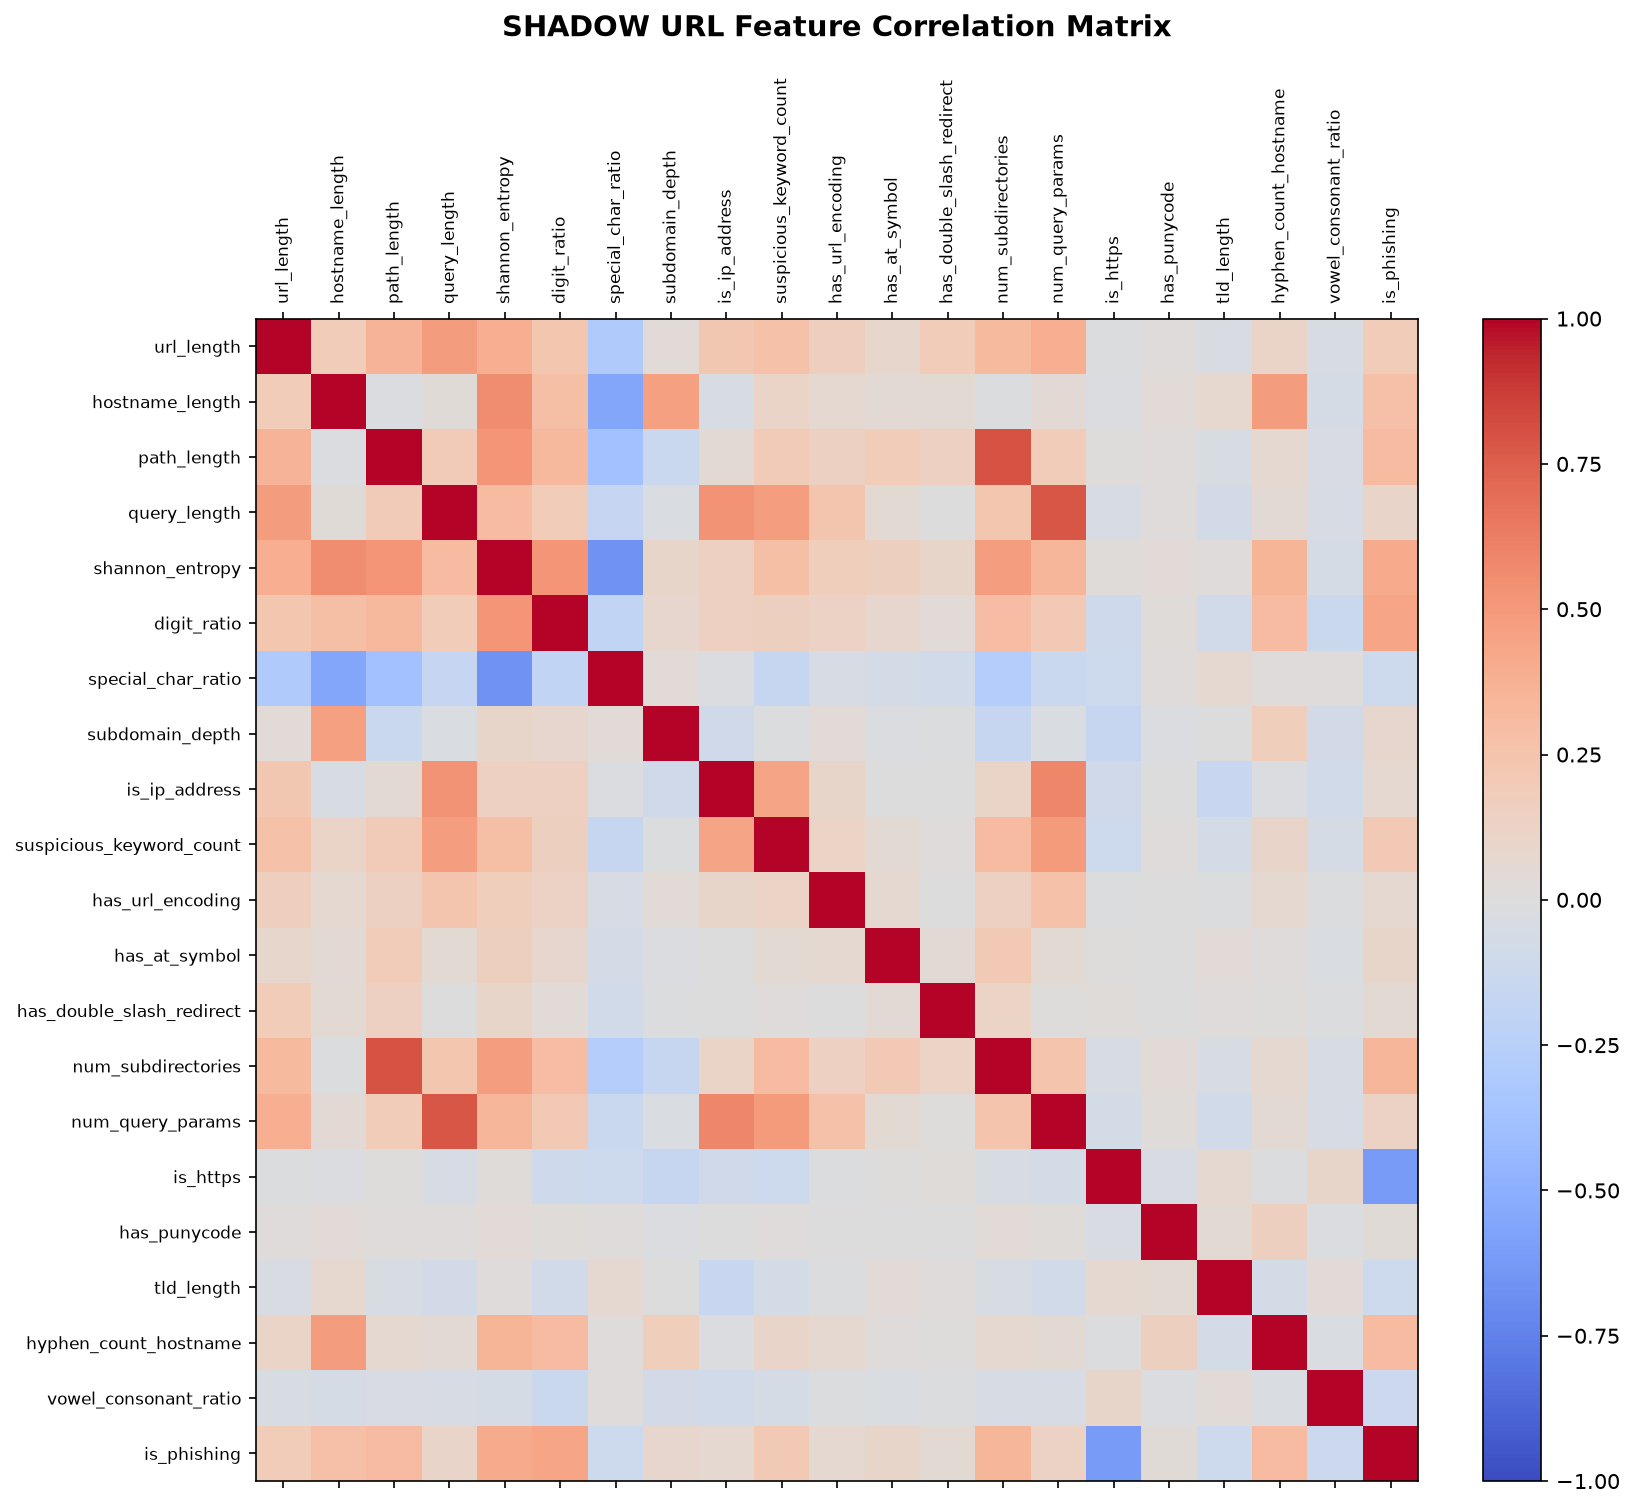

In [10]:
# 1. Missing Value Audit
print("=== Missing Value Audit ===")
print("URL Features Missing Count:", df_url_features.isnull().sum().sum())
print("HTML Features Missing Count:", df_html_features.isnull().sum().sum())
print("ResNet-18 NaN Check:", np.isnan(r18_mat).sum())
print("MobileNetV3 NaN Check:", np.isnan(mv3_mat).sum())
print("Behaviour Features Missing Count:", df_behaviour.isnull().sum().sum())

# 2. Correlation Analysis on URL Features
numeric_url_cols = [c for c in df_url_features.select_dtypes(include=[np.number]).columns if c != "is_phishing"]
corr_matrix = df_url_features[numeric_url_cols + ["is_phishing"]].corr()

plt.figure(figsize=(14, 10))
cax = plt.matshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, fignum=1)
plt.colorbar(cax, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90, fontsize=8)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns, fontsize=8)
plt.title("SHADOW URL Feature Correlation Matrix", fontsize=14, fontweight="bold", pad=20)
fig_path = FIGURES_DIR / "notebook03_url_feature_correlations.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved correlation heatmap to: {fig_path.name}")

# 3. Top Correlated Features with Phishing Target
top_url_corr = corr_matrix["is_phishing"].drop("is_phishing").abs().sort_values(ascending=False)
print()
print("Top 10 URL Features Most Correlated with Phishing Status:")
for feat, score in top_url_corr.head(10).items():
    raw_corr = corr_matrix.loc[feat, "is_phishing"]
    print(f"  - {feat:30s}: r = {raw_corr:+.4f} (|r| = {score:.4f})")


<string>:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
Saved distribution plots to: notebook03_feature_distributions.png


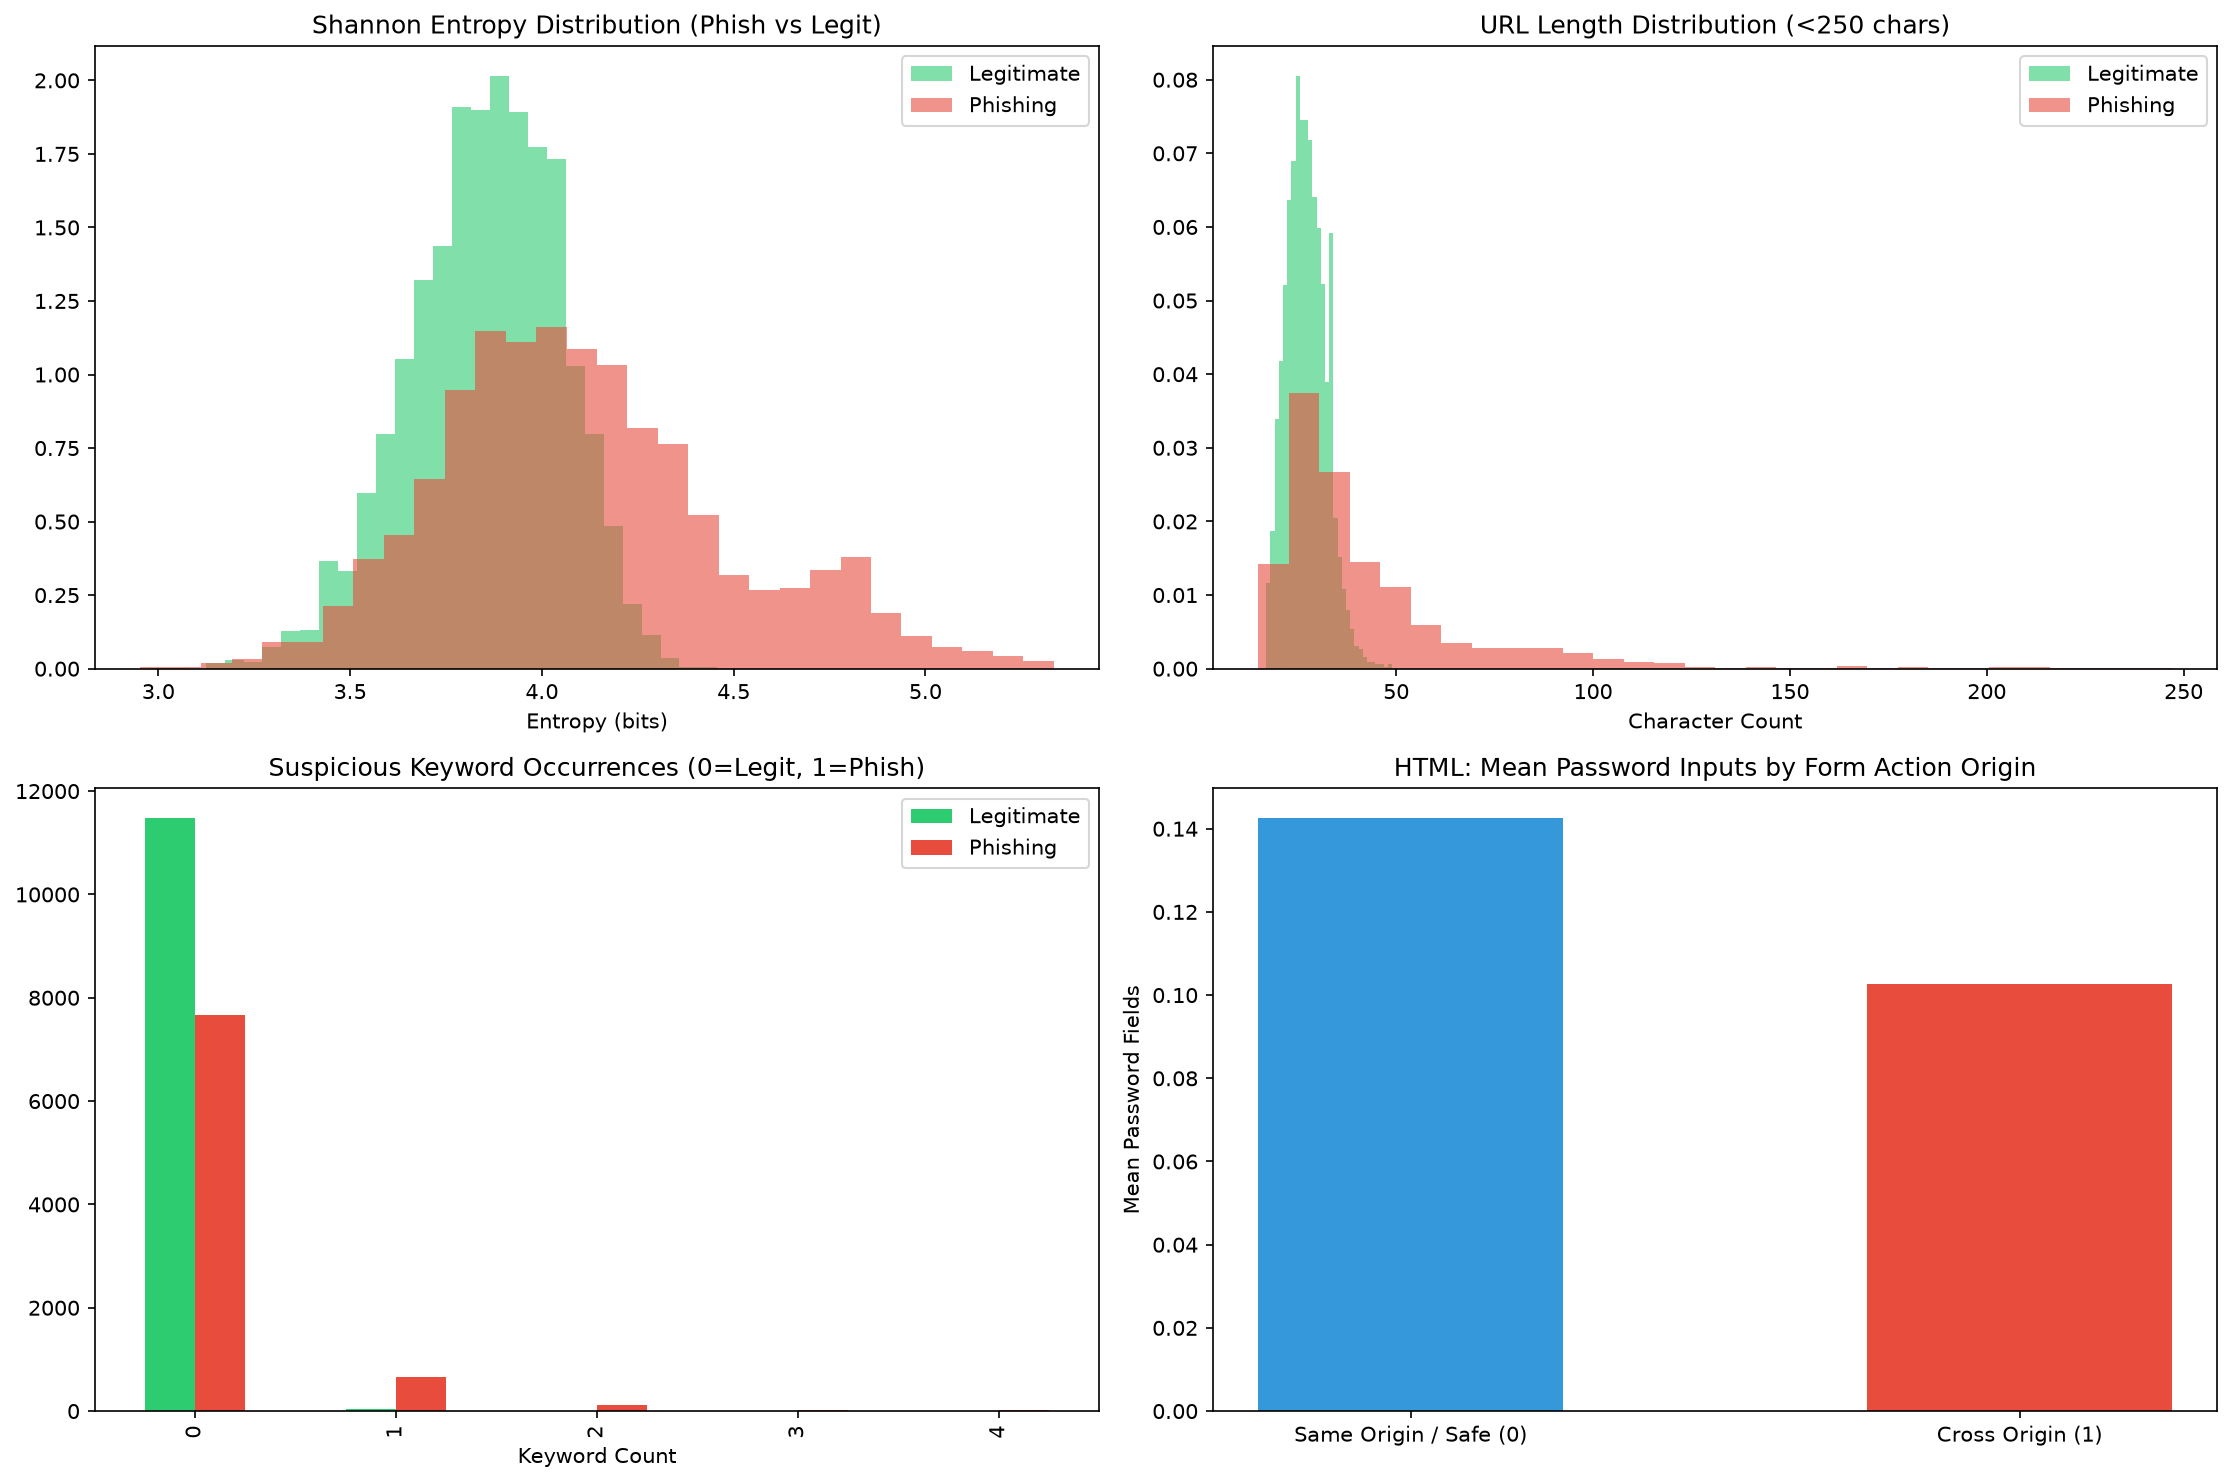

In [11]:
# 4. Distribution Comparison for Key Features
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Shannon Entropy Histogram
phish_entropy = df_url_features[df_url_features["is_phishing"] == 1]["shannon_entropy"]
legit_entropy = df_url_features[df_url_features["is_phishing"] == 0]["shannon_entropy"]
axes[0, 0].hist(legit_entropy, bins=30, alpha=0.6, label="Legitimate", color="#2ecc71", density=True)
axes[0, 0].hist(phish_entropy, bins=30, alpha=0.6, label="Phishing", color="#e74c3c", density=True)
axes[0, 0].set_title("Shannon Entropy Distribution (Phish vs Legit)")
axes[0, 0].set_xlabel("Entropy (bits)")
axes[0, 0].legend()

# URL Length Histogram (<250 chars)
phish_len = df_url_features[(df_url_features["is_phishing"] == 1) & (df_url_features["url_length"] < 250)]["url_length"]
legit_len = df_url_features[(df_url_features["is_phishing"] == 0) & (df_url_features["url_length"] < 250)]["url_length"]
axes[0, 1].hist(legit_len, bins=30, alpha=0.6, label="Legitimate", color="#2ecc71", density=True)
axes[0, 1].hist(phish_len, bins=30, alpha=0.6, label="Phishing", color="#e74c3c", density=True)
axes[0, 1].set_title("URL Length Distribution (<250 chars)")
axes[0, 1].set_xlabel("Character Count")
axes[0, 1].legend()

# Suspicious Keyword Count Bar Chart
kw_df = df_url_features.groupby(["suspicious_keyword_count", "is_phishing"]).size().unstack(fill_value=0)
kw_df.plot(kind="bar", stacked=False, color=["#2ecc71", "#e74c3c"], ax=axes[1, 0])
axes[1, 0].set_title("Suspicious Keyword Occurrences (0=Legit, 1=Phish)")
axes[1, 0].set_xlabel("Keyword Count")
axes[1, 0].legend(["Legitimate", "Phishing"])

# HTML Password Inputs by Cross-Origin Form Status in PhreshPhish
pw_co = df_html_features.groupby("has_cross_origin_form")["num_password_inputs"].mean()
axes[1, 1].bar([0, 1], pw_co.values, color=["#3498db", "#e74c3c"], width=0.5)
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(["Same Origin / Safe (0)", "Cross Origin (1)"])
axes[1, 1].set_title("HTML: Mean Password Inputs by Form Action Origin")
axes[1, 1].set_ylabel("Mean Password Fields")

plt.tight_layout()
fig_dist_path = FIGURES_DIR / "notebook03_feature_distributions.png"
plt.savefig(fig_dist_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved distribution plots to: {fig_dist_path.name}")


---
## 9. Section 6 — Reproducibility, Artifact Exports & Preprocessing Manifest

We serialize all extracted feature datasets into Apache Parquet format inside `data/processed/` and `data/interim/`, generate the official **SHADOW Feature Catalogue**, and record all execution metadata in the project manifest.


In [12]:
# 1. Save URL Feature Dataset
url_feat_out = DATA_PROCESSED / "url_features_extracted.parquet"
df_url_features.to_parquet(url_feat_out, index=False)
print(f"[Exported] {url_feat_out.relative_to(PROJECT_ROOT)} ({url_feat_out.stat().st_size / (1024*1024):.2f} MB)")

# 2. Save HTML Feature Dataset
html_feat_out = DATA_PROCESSED / "html_features_extracted.parquet"
df_html_features.to_parquet(html_feat_out, index=False)
print(f"[Exported] {html_feat_out.relative_to(PROJECT_ROOT)} ({html_feat_out.stat().st_size / (1024*1024):.2f} MB)")

# 3. Save Visual Embeddings (ResNet-18 & MobileNetV3)
df_vis_export = df_vis_extracted[["url", "registered_domain", "is_phishing", "screenshot_path"]].copy()
# Save embeddings as float32 matrices
for dim in range(min(32, r18_mat.shape[1])): # store first 32 preview dims directly in parquet
    df_vis_export[f"r18_dim_{dim}"] = r18_mat[:, dim]
for dim in range(min(32, mv3_mat.shape[1])):
    df_vis_export[f"mv3_dim_{dim}"] = mv3_mat[:, dim]

vis_feat_out = DATA_PROCESSED / "visual_embeddings_sample.parquet"
df_vis_export.to_parquet(vis_feat_out, index=False)
np.save(DATA_PROCESSED / "resnet18_embeddings_1000.npy", r18_mat)
np.save(DATA_PROCESSED / "mobilenetv3_embeddings_1000.npy", mv3_mat)
print(f"[Exported] {vis_feat_out.relative_to(PROJECT_ROOT)} ({vis_feat_out.stat().st_size / (1024*1024):.2f} MB)")
print(f"[Exported] Full numpy matrices: resnet18_embeddings_1000.npy ({r18_mat.nbytes / (1024*1024):.2f} MB), mobilenetv3_embeddings_1000.npy ({mv3_mat.nbytes / (1024*1024):.2f} MB)")

# 4. Save Behaviour Telemetry Schema & Dataset
beh_feat_out = DATA_INTERIM / "behaviour_features_synthetic.parquet"
df_behaviour.to_parquet(beh_feat_out, index=False)
print(f"[Exported] {beh_feat_out.relative_to(PROJECT_ROOT)} ({beh_feat_out.stat().st_size / (1024*1024):.2f} MB)")


[Exported] data\processed\url_features_extracted.parquet (0.97 MB)
[Exported] data\processed\html_features_extracted.parquet (0.14 MB)
[Exported] data\processed\visual_embeddings_sample.parquet (0.34 MB)
[Exported] Full numpy matrices: resnet18_embeddings_1000.npy (1.95 MB), mobilenetv3_embeddings_1000.npy (2.20 MB)
[Exported] data\interim\behaviour_features_synthetic.parquet (0.02 MB)


In [13]:
# Update Preprocessing & Feature Manifest
manifest_path = REPORTS_DIR / "preprocessing_manifest.json"
manifest_data = {}
if manifest_path.exists():
    with open(manifest_path, "r", encoding="utf-8") as f:
        manifest_data = json.load(f)

manifest_data["notebook03_execution"] = {
    "timestamp": pd.Timestamp.now().isoformat(),
    "python_version": platform.python_version(),
    "pytorch_version": torch.__version__,
    "cuda_device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None (CPU)",
    "url_features": {
        "count": len(numeric_url_cols),
        "evaluated_samples": len(df_url_features),
        "throughput_urls_per_sec": round(sample_size / extraction_time, 1),
        "output_file": str(url_feat_out.relative_to(PROJECT_ROOT))
    },
    "html_features": {
        "count": df_html_features.shape[1] - 4,
        "evaluated_samples": len(df_html_features),
        "throughput_pages_per_sec": round(len(df_phresh) / t_html, 1),
        "output_file": str(html_feat_out.relative_to(PROJECT_ROOT))
    },
    "visual_embeddings": {
        "resnet18_dimensions": r18_mat.shape[1],
        "mobilenetv3_dimensions": mv3_mat.shape[1],
        "evaluated_samples": len(df_vis_extracted),
        "throughput_images_per_sec": round(len(df_vis_extracted) / total_vis_time, 1),
        "output_parquet": str(vis_feat_out.relative_to(PROJECT_ROOT))
    },
    "behaviour_schema": {
        "scenarios_simulated": len(scenarios),
        "total_records": len(df_behaviour),
        "output_file": str(beh_feat_out.relative_to(PROJECT_ROOT))
    }
}

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest_data, f, indent=2)

print("Updated Preprocessing & Feature Manifest successfully saved.")


Updated Preprocessing & Feature Manifest successfully saved.
